# 01 – Chuẩn bị dữ liệu (B0 → B5)

Notebook chung của nhóm. Mỗi phần B0…B5 do một người viết (xem `PIPELINE_DO_AN_ML.md`, mục 3).

---
## B0. Định nghĩa bài toán và thang đo *(Người 3)*

### B0.1 Bài toán

| | |
|---|---|
| **Loại bài toán** | Hồi quy có giám sát |
| **Đơn vị quan sát** | Một sản phẩm tai nghe Bluetooth đang bán trên Lazada.vn (một `item_id`) |
| **Thời điểm dự đoán** | Lúc người bán **vừa đăng** sản phẩm. Chỉ dùng thông tin có sẵn lúc đó: tên, thương hiệu, thông số, thông tin shop, % giảm giá |
| **Đầu ra** | Giá bán `price` (VNĐ). Mô hình học **`log10(price)`**, kết quả báo cáo đổi lại về VNĐ |
| **Ứng dụng** | (1) Người bán mới nhập thông tin sản phẩm → nhận giá gợi ý. (2) Người mua phát hiện sản phẩm bị định giá quá cao so với sản phẩm tương tự |

**Hệ quả của "thời điểm dự đoán":** mọi cột chỉ có sau khi sản phẩm đã bán một thời gian (lượt bán, số đánh giá, điểm sao, tỉ lệ mua lại, thứ hạng tìm kiếm) và cột chứa sẵn đáp án (`original_price`: giá gốc × (1 − % giảm) = giá) đều là **rò rỉ dữ liệu** và bị loại. Danh sách nằm ở `chung.COT_RO_RI`; Người 2 kiểm tra lại ở B2.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import chung

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
raw = pd.read_csv('../data/raw/lazada_tai_nghe_1500.csv')
print(raw.shape)
print('Cột rò rỉ có trong dữ liệu:', [c for c in chung.COT_RO_RI if c in raw.columns])

(1550, 73)
Cột rò rỉ có trong dữ liệu: ['price', 'original_price', 'discount_raw', 'rating_score', 'review_count', 'sold_raw', 'sold_num', 'rating_avg_detail', 'rating_count_detail', 'star_1', 'star_2', 'star_3', 'star_4', 'star_5', 'repurchase_rate', 'returning_customers', 'reviews_with_media', 'review_tag_repurchase', 'review_tags_raw', 'search_page', 'rank_in_page']


### B0.2 Biến mục tiêu: vì sao dùng `log10(price)`

Dùng dữ liệu sau `chung.lam_sach` (bỏ ngoại lệ giá theo Tukey 3×IQR trên log, dẫn chứng ở B1.2) để xem phân phối (luật làm sạch chính thức ở B1, dùng đúng hàm `chung.lam_sach`).

In [2]:
df = chung.lam_sach(raw)[0]
print(f'Sau làm sạch: {len(df)} dòng')

tom_tat = pd.DataFrame({
    'price (VNĐ)': df['price'].describe(),
    'log10(price)': df[chung.TARGET].describe(),
}).T
tom_tat['skew'] = [df['price'].skew(), df[chung.TARGET].skew()]
tom_tat

Sau làm sạch: 1545 dòng


,count,mean,std,min,25%,50%,75%,max,skew
price (VNĐ),"1,545.000","431,162.497","795,976.019","15,000.000","127,800.000","223,439.000","456,000.000","14,990,000.000",8.246
log10(price),"1,545.000",5.384,0.431,4.176,5.107,5.349,5.659,7.176,0.403


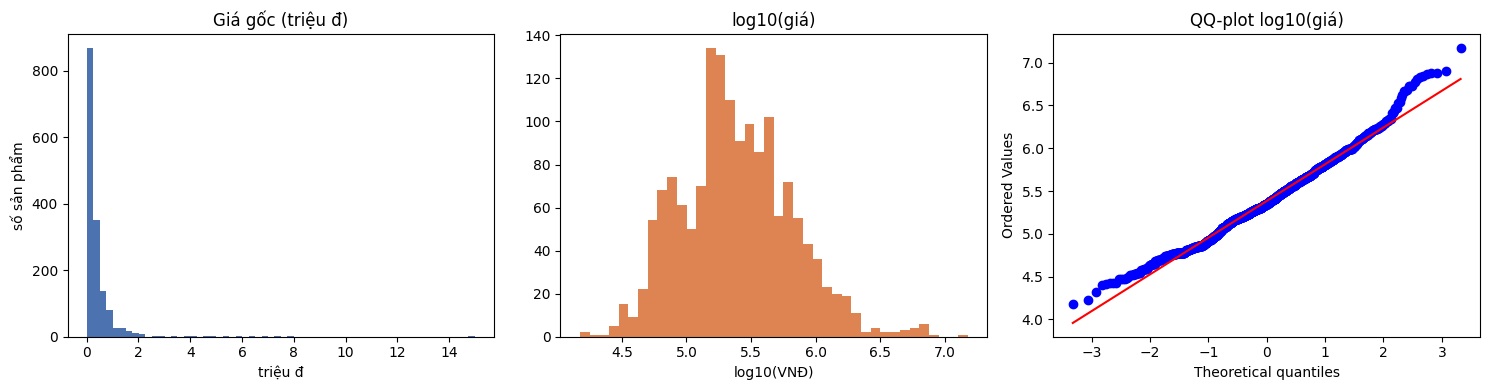

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df['price'] / 1e6, bins=60, color='#4C72B0')
ax[0].set(title='Giá gốc (triệu đ)', xlabel='triệu đ', ylabel='số sản phẩm')
ax[1].hist(df[chung.TARGET], bins=40, color='#DD8452')
ax[1].set(title='log10(giá)', xlabel='log10(VNĐ)')
stats.probplot(df[chung.TARGET], dist='norm', plot=ax[2])
ax[2].set_title('QQ-plot log10(giá)')
plt.tight_layout(); plt.show()

**Nhận xét:**
- Giá gốc lệch phải rất mạnh (skew ở bảng trên): đa số dưới 500 nghìn nhưng đuôi kéo tới hàng chục triệu. Nếu học trên giá gốc, MSE bị vài sản phẩm đắt chi phối; sai 100k với tai nghe 150k (67%) bị xem nhẹ hơn sai 200k với tai nghe 5 triệu (4%).
- Sau `log10`, phân phối gần đối xứng (skew xấp xỉ 0,5), QQ-plot gần thẳng. Sai số trên log là **sai số tương đối**, đều giữa hàng rẻ và hàng đắt, đúng với cách người mua nhìn giá.
- Chọn **log10** thay vì ln để dễ đọc: 5 = 100 nghìn, 6 = 1 triệu. So sánh định lượng log vs giá gốc (KB-C-07) chạy sau khi có `abt_gia.csv`.

### B0.3 Thang đo

| Thang đo | Vai trò | Hàm trong `chung.py` | Cách đọc |
|---|---|---|---|
| **RMSE trên log10(giá)** | **Chính**: chọn mô hình, tinh chỉnh (`scoring="neg_root_mean_squared_error"`) | `rmse_log` | Nhỏ hơn tốt hơn. `10**RMSE` = giá dự đoán thường lệch bao nhiêu lần |
| R² (trên log) | Phụ | `r2_log` | Tỉ lệ biến thiên của log giá được giải thích |
| MAE (VNĐ) | Phụ, dễ hiểu với người bán | `mae_vnd` | Lệch trung bình bao nhiêu đồng (bị hàng đắt kéo lên) |
| MAPE (%) | Phụ | `mape` | Lệch trung bình bao nhiêu % |
| % trúng ±20% | Phụ, gắn với ứng dụng | `ty_le_trung_20` | Bao nhiêu % sản phẩm có giá gợi ý lệch dưới 20% |

`chung.tinh_thang_do(y_true_log, y_pred_log)` trả cả 5 thang đo với tên khóa thống nhất; `danh_gia_cv` ở B5 sẽ gọi hàm này.

**Vì sao RMSE log là thang đo chính:** khớp với hàm mất mát của hầu hết mô hình (bình phương sai số), không bị hàng đắt chi phối như MAE VNĐ, và phạt nặng các lần đoán lệch xa (quan trọng vì giá gợi ý lệch gấp đôi là không dùng được).

In [4]:
# Diễn giải RMSE log10 thành "lệch bao nhiêu lần"
pd.DataFrame({'rmse_log': [0.439, 0.380, 0.343, 0.307, 0.282, 0.266]},
             index=['Dummy (trung vị)', 'Trung vị theo thương hiệu', 'Linear', 'Ridge + TF-IDF (mốc B6)', 'mục tiêu R² 0,55 (≈ 0,42·√0,45)', 'rất tốt R² 0,60']
            ).assign(lech_x_lan=lambda d: d['rmse_log'].map(chung.he_so_sai))

,rmse_log,lech_x_lan
Dummy (trung vị),0.439,2.748
Trung vị theo thương hiệu,0.380,2.399
Linear,0.343,2.203
Ridge + TF-IDF (mốc B6),0.307,2.028
"mục tiêu R² 0,55 (≈ 0,42·√0,45)",0.282,1.914
"rất tốt R² 0,60",0.266,1.845


In [5]:
# Kiểm tra nhanh các hàm thang đo (KHÔNG phải baseline chính thức, baseline làm ở B5 với CV)
y = df[chung.TARGET].to_numpy()
du_doan_trung_vi = np.full_like(y, np.median(y))
du_doan_hoan_hao = y.copy()
du_doan_gap_doi = y + np.log10(2)   # đoán mọi giá gấp đôi
pd.DataFrame({'trung vị toàn bộ': chung.tinh_thang_do(y, du_doan_trung_vi),
              'hoàn hảo': chung.tinh_thang_do(y, du_doan_hoan_hao),
              'luôn gấp đôi': chung.tinh_thang_do(y, du_doan_gap_doi)}).T

,rmse_log,r2,mae_vnd,mape_pct,trung_20_pct
trung vị toàn bộ,0.432,-0.007,"306,376.650",92.353,16.699
hoàn hảo,0.000,1.000,0.000,0.000,100.000
luôn gấp đôi,0.301,0.512,"431,162.497",100.000,0.000


Hàm chạy đúng như kỳ vọng: dự đoán hoàn hảo cho RMSE 0, R² 1, trúng 100%; đoán gấp đôi cho RMSE log = log10(2) ≈ 0,301, MAPE 100%.

### B0.4 Mục tiêu đặt trước và quy tắc chọn mô hình

- **Giao thức chấm:** CV `GroupKFold(5)` theo shop trên 80% train (cột `fold` do Người 2 tạo ở B4). Luôn báo cáo kèm điểm KFold ngẫu nhiên để thấy mức "đẹp giả".
- **Mốc phải thắng** (KB-C-03, thử nhanh 26/11): RMSE log < **0,307** (Ridge + TF-IDF tên, R² 0,49).
- **Mục tiêu:** R² ≥ **0,55** theo GroupKFold là "tốt", ≥ 0,60 là "rất tốt". Không đặt 0,70: lần thử trước đạt 0,58 là do chia ngẫu nhiên (cùng shop ở cả train và test); chia theo shop thì Linear chỉ đạt 0,36.
- **Quy tắc chọn:** mô hình có RMSE log CV trung bình thấp nhất. Nếu chênh lệch nhỏ hơn độ lệch chuẩn qua fold (hoặc t-test ghép cặp ở B7 có p ≥ 0,05) thì coi là ngang nhau và chọn mô hình **đơn giản / nhanh hơn**.
- **Tập test** chỉ mở một lần ở B7.
- ⭐ Bài toán phụ phân loại phân khúc giá (rẻ / trung / cao): chỉ làm nếu thầy yêu cầu.

---
## B1. Làm sạch dữ liệu *(Người 1)*

- **Nguồn:** tự cào Lazada.vn, 2 đợt (13/11: 444 dòng, 19/11: 1.106 dòng), 5 từ khóa. Bộ chính thức `data/raw/lazada_tai_nghe_1500.csv`.
- **Nguyên tắc:** mọi luật nằm trong `chung.lam_sach()` để B3 và demo dùng lại đúng một cách. Luật chỉ dùng thông tin **của chính dòng đó** (các ngưỡng là hằng số cố định), nên làm trước khi chia train/test mà không rò rỉ. Luật nào cũng có dẫn chứng ở mục tương ứng bên dưới.
- **Ranh giới với B2/B3:** B1 chỉ sửa cái **sai** (trùng, sai đơn vị, sai chính tả, giá trị vô lý). Chọn cột, điền khuyết, cắt trần, lấy log, tạo đặc trưng thuộc B2/B3.

| Nhóm | Luật | Mục |
|---|---|---|
| A. Chuẩn hóa chuỗi | A1 bỏ BOM/tab/khoảng trắng thừa · A2 giá trị giữ chỗ ("Info Unavailable", "default"…) → trống · A3 gộp cách viết tên shop · A4 gộp tên nơi bán | B1.3 |
| B. Bỏ dòng | 1 trùng `item_id` · 2 tin đăng trùng (cùng tên + shop + giá) · 3 ngoại lệ giá (Tukey 3×IQR trên log) | B1.2 |
| C. Sửa giá trị sai | C1 `product_type` sai danh mục · C2 thông số ghi nhầm đơn vị · C3 thông số ngoài khoảng hợp lệ · C4–C5 chuẩn hóa và điền thương hiệu · C6 mã IP | B1.2, B1.4, B1.5 |
| D. Cờ | `sai_danh_muc`, `thieu_chi_tiet`, `dot_cao` | B1.6 |

### B1.0 Rà soát dữ liệu thô

Trước khi đặt luật: kiểu dữ liệu, tỉ lệ trống, và **trống theo đợt cào** (cột trống vì đợt cào không lấy khác với cột trống vì shop không khai).

In [6]:
raw = pd.read_csv('../' + chung.DUONG_DAN_THO)
print('Kích thước:', raw.shape, '| item_id duy nhất:', raw['item_id'].is_unique)
print('Cột bắt buộc trống (name, price, url):', raw[['name', 'price', 'url']].isna().sum().to_dict())
tong_quan = pd.DataFrame({'kiểu': raw.dtypes.astype(str), '% trống': (raw.isna().mean() * 100).round(1),
                          'số giá trị khác nhau': raw.nunique()})
print('\nCột trống hoàn toàn hoặc chỉ có 1 giá trị:')
print(tong_quan[(tong_quan['% trống'] == 100) | (tong_quan['số giá trị khác nhau'] <= 1)])

Kích thước: (1550, 73) | item_id duy nhất: True
Cột bắt buộc trống (name, price, url): {'name': 0, 'price': 0, 'url': 0}

Cột trống hoàn toàn hoặc chỉ có 1 giá trị:
                       kiểu  % trống  số giá trị khác nhau
is_freeship         float64   71.400                     1
is_sponsored        float64   71.400                     1
in_stock            float64   71.400                     1
chat_response_rate  float64  100.000                     0
is_new_seller       float64    9.900                     1


In [7]:
# % có dữ liệu theo đợt cào: cột bằng 0 ở một đợt là do cách cào, không phải do sản phẩm
dot = raw['crawl_time'].str[:10]
cot_xem = ['sku_id', 'is_lazmall', 'is_freeship', 'in_stock', 'original_price', 'rating_score', 'sold_num',
           'seller_name', 'shop_age_years', 'battery_hours_num', 'bluetooth_version_num']
(raw.groupby(dot)[cot_xem].apply(lambda g: g.notna().mean() * 100).round(0).T
    .rename(columns=lambda d: f'đợt {d} (%)'))

crawl_time,đợt 2026-11-13 (%),đợt 2026-11-19 (%)
sku_id,100.000,0.000
is_lazmall,100.000,0.000
is_freeship,100.000,0.000
in_stock,100.000,0.000
original_price,95.000,88.000
rating_score,94.000,49.000
sold_num,91.000,53.000
seller_name,100.000,86.000
shop_age_years,61.000,36.000
battery_hours_num,39.000,25.000


**Nhận xét:** `chat_response_rate` trống 100%; `is_sponsored`, `is_freeship`, `in_stock`, `is_new_seller` chỉ có 1 giá trị; `sku_id`, `is_lazmall`… chỉ có ở đợt 13/11. Đây là vấn đề **chọn cột**, chuyển cho B2 (B1 không xóa cột).

### B1.1 Kết quả làm sạch

In [8]:
sach, nhat_ky_dong, nhat_ky_sua = chung.lam_sach(raw)
pd.DataFrame(nhat_ky_dong, columns=['Bước', 'Số dòng bỏ', 'Số dòng còn'])

,Bước,Số dòng bỏ,Số dòng còn
0,0. Dữ liệu thô,0,1550
1,1. Bỏ trùng item_id,0,1550
2,2. Bỏ tin đăng trùng (cùng tên + shop + giá),4,1546
3,"3. Bỏ ngoại lệ giá (ngoài 3,000 – 20,000,000 đ)",1,1545


In [9]:
sua = pd.DataFrame(nhat_ky_sua, columns=['Luật', 'Cột', 'Số ô bị sửa'])
sua[sua['Số ô bị sửa'] > 0].reset_index(drop=True)

,Luật,Cột,Số ô bị sửa
0,A1. Bỏ BOM/tab/khoảng trắng thừa,name,75
1,A1. Bỏ BOM/tab/khoảng trắng thừa,seller_name,14
2,A2. Giá trị giữ chỗ → trống,bluetooth_version,31
3,A2. Giá trị giữ chỗ → trống,waterproof,1
4,A2. Giá trị giữ chỗ → trống,model,3
5,A2. Giá trị giữ chỗ → trống,driver_type,65
6,A2. Giá trị giữ chỗ → trống,impedance,131
7,A4. Gộp tên nơi bán,location,4
8,C1. product_type sai danh mục → trống,product_type,35
9,"C2. Trở kháng ghi nhầm đơn vị (mm, dB) → trống",impedance_ohm,7


### B1.2 Luật bỏ dòng

**Luật 2 – Tin đăng trùng.** `item_id` không trùng, nhưng có shop đăng lại **y hệt** một sản phẩm (cùng tên, cùng giá) dưới mã khác. Với mô hình, đó là 2 dòng giống hệt cả đặc trưng lẫn đáp án, làm tăng trọng số giả cho sản phẩm đó.

In [10]:
chuan = raw.assign(name=chung._chuan_hoa_chuoi(raw['name']), seller_name=chung._chuan_hoa_chuoi(raw['seller_name']))
trung = chuan[chuan.duplicated(['name', 'seller_name', 'price'], keep=False)].sort_values(['name', 'item_id'])
so_cap = trung.groupby(['name', 'price']).ngroups
print(f'{len(trung)} dòng = {so_cap} cặp → bỏ {len(trung) - so_cap} bản sao')
trung[['item_id', 'price', 'seller_name', 'crawl_time', 'search_query']].assign(name=trung['name'].str[:60]).style.format({'price': '{:,.0f}'})

8 dòng = 4 cặp → bỏ 4 bản sao


,item_id,price,seller_name,crawl_time,search_query,name
1537,13468314499,"164,000",Prime Supply_Play Life,2026-11-19T12:40:07.483Z,tai nghe true wireless,"CHUBAN | Tai Nghe Bluetooth TWS 5.3 Độ Trễ Thấp 65ms, Tai Ng"
1508,13478770135,"164,000",Prime Supply_Play Life,2026-11-19T12:39:46.077Z,tai nghe true wireless,"CHUBAN | Tai Nghe Bluetooth TWS 5.3 Độ Trễ Thấp 65ms, Tai Ng"
1519,13450355653,"148,000",Prime Supply_Play Life,2026-11-19T12:39:46.078Z,tai nghe true wireless,CHUBAN | Tai Nghe Bluetooth Trong Tai Màn Hình Kỹ Thuật Số T
1476,13465456714,"148,000",Prime Supply_Play Life,2026-11-19T12:39:22.521Z,tai nghe true wireless,CHUBAN | Tai Nghe Bluetooth Trong Tai Màn Hình Kỹ Thuật Số T
1371,13463173669,"149,000",nan,2026-11-19T12:37:49.441Z,tai nghe chụp tai bluetooth,Tai Nghe Bluetooth 5.0 Không Dây Có Thể Gập Lại Tai Nghe Ove
1356,13465518327,"149,000",nan,2026-11-19T12:37:34.845Z,tai nghe chụp tai bluetooth,Tai Nghe Bluetooth 5.0 Không Dây Có Thể Gập Lại Tai Nghe Ove
1292,13442171681,"199,000",Prime Supply_Play Life,2026-11-19T12:37:11.556Z,tai nghe chụp tai bluetooth,Tai Nghe Bluetooth Không Dây HIFI Stereo Over Ear Với Mic HD
1294,13444146087,"199,000",Prime Supply_Play Life,2026-11-19T12:37:11.556Z,tai nghe chụp tai bluetooth,Tai Nghe Bluetooth Không Dây HIFI Stereo Over Ear Với Mic HD


Các cặp được cào cách nhau vài giây trong cùng từ khóa. Một cặp không có tên shop (dòng timeout) nhưng trùng tên dài và giá đến từng đồng, nên cũng coi là bản sao.

Chỉ bỏ khi trùng **cả tên, shop và giá**. Cùng tên + cùng shop nhưng **khác giá** (vd. hai phiên bản) thì giữ, vì đó là hai mức giá thật; GroupKFold theo shop giữ chúng cùng một phía.

**Không bỏ dòng nào vì "không phải tai nghe".** Pipeline ban đầu định bỏ các dòng có `product_type` lạ. Kiểm tra ba cách:

In [11]:
la_tn = raw['product_type'].isin(chung.LOAI_TAI_NGHE) | raw['product_type'].isna()
ten = raw['name'].str.lower()
co_tu_khoa = ten.str.contains(r'tai\s*nghe|headphone|headset|earphone|earbud|\btws\b|\bows\b|airpods|buds')
chi_co_day = ten.str.contains('có dây') & ~ten.str.contains('bluetooth|không dây|wireless|tws')
print(f'(1) product_type không phải tai nghe: {(~la_tn).sum()} dòng, {raw.loc[~la_tn, "product_type"].nunique()} danh mục')
print(f'(2) tên không chứa từ khóa tai nghe : {(~co_tu_khoa).sum()} dòng →', raw.loc[~co_tu_khoa, 'name'].str[:60].tolist())
print(f'(3) tai nghe chỉ có dây (không Bluetooth): {chi_co_day.sum()} dòng')
raw.loc[~la_tn, ['product_type', 'price']].assign(name=raw['name'].str[:70]).head(12).style.format({'price': '{:,.0f}'})

(1) product_type không phải tai nghe: 35 dòng, 23 danh mục
(2) tên không chứa từ khóa tai nghe : 4 dòng → ['Tai Phone Bluetooth Không Dây Ultrapods Pro v5.3 Đầy Dủ Tính', 'Tai Nge Bluetooth Không Dây cảm ứng Ultrapods Pro bass hay, ', 'Tai Phone  Bluetooth Chụp Tai Cao Cấp B39 - Bass cực mạnh, P', 'Tai đôi DX-16 mới, hai cặp nghe, Bluetooth 5.5, nghe nhét ta']
(3) tai nghe chỉ có dây (không Bluetooth): 0 dòng


,product_type,price,name
9,Phụ kiện thời trang khác,"52,000",SEA JJT Tai nghe không dây Pro4 TWS với pin lâu và độ trễ thấp
34,Phụ kiện thiết bị âm thanh di động,"2,090,000","Tai Nghe Bluetooth Anker soundcore Liberty 5, Chống Ồn Chủ Động, Âm Th"
56,Phụ kiện mũ bảo hiểm,"137,100","【FORESIGHT 】Tai Nghe Bluetooth Y10 Cho Mũ Bảo Hiểm Xe Máy, IPX6 Chống"
68,Phụ kiện tóc nữ,"61,740",VINTLOOK Mới không Dây M10 Tai Nghe Bluetooth HD chất lượng âm thanh t
74,Micro,"76,377",JINHF Clip-on Tai nghe bluetooth thoải mái mở tai HD Mic hiển thị kỹ t
172,Phụ kiện treo điện thoại,"50,000","Tai nghe Bluetooth Pro4 với âm thanh HiFi, thời lượng pin dài, giảm ti"
193,Thắt lưng nữ,"55,100",STAR FRUIT Pro5s không dây trong tai tai nghe gắn tai Bluetooth với tu
242,Mật Ong,"55,100",STAR FRUIT Tai nghe bluetooth không dây với tuổi thọ pin dài màn hình
266,Phụ kiện thời trang khác,"65,000",Calcenubes Tai nghe bluetooth không dây với màn hình LED và tuổi thọ p
301,Phụ kiện thời trang khác,"105,000",Clemine Tai nghe Bluetooth không dây thiết kế máy ảnh retro với thời l


35 dòng có danh mục lạ ("Mật Ong", "Thắt lưng nữ", "Bình nước thể thao"…) đọc tên thì **đều là tai nghe Bluetooth thật** (Anker Liberty 5, Bose QC Ultra, Redmi Buds 6, KZ AN01…), chỉ là shop chọn sai danh mục. 4 tên không có từ khóa cũng là tai nghe: "Tai Phone" (2), gõ sai "Tai Nge", và "Tai đôi DX-16". Không có tai nghe chỉ có dây. → **Giữ dòng**, chỉ xóa `product_type` sai (luật C1) và gắn cờ `sai_danh_muc`.

**Luật 3 – Ngưỡng ngoại lệ giá: dẫn chứng**

Câu hỏi: dòng nào là **ngoại lệ thật** (sai, không đại diện, làm méo mô hình), dòng nào chỉ là hàng rẻ/đắt hợp lệ? Trả lời bằng 3 loại bằng chứng: (1) quy tắc thống kê, (2) khoảng trống trong phân phối, (3) đọc từng sản phẩm ở hai đầu.

**(1) Quy tắc thống kê.** Tính trên `log10(price)` vì giá gốc lệch phải rất mạnh: trên thang VNĐ, Tukey coi mọi sản phẩm trên ~950k là ngoại lệ (135 dòng, gồm cả AirPods, Sony), rõ ràng vô lý.

In [12]:
y_raw = np.log10(raw['price'])
q1, q3 = y_raw.quantile([.25, .75]); iqr = q3 - q1
med = y_raw.median(); mad = (y_raw - med).abs().median() / 0.6745
q1v, q3v = raw['price'].quantile([.25, .75])
quy_tac = {
    'Tukey 1,5×IQR (thang VNĐ)': (q1v - 1.5 * (q3v - q1v), q3v + 1.5 * (q3v - q1v)),
    'Tukey 1,5×IQR (log)': (10 ** (q1 - 1.5 * iqr), 10 ** (q3 + 1.5 * iqr)),
    'Tukey 3×IQR (log) – ngoại lệ cực đoan': (10 ** (q1 - 3 * iqr), 10 ** (q3 + 3 * iqr)),
    'z-score > 3 (log)': (10 ** (y_raw.mean() - 3 * y_raw.std()), 10 ** (y_raw.mean() + 3 * y_raw.std())),
    'MAD z > 3,5 (log, Iglewicz–Hoaglin)': (10 ** (med - 3.5 * mad), 10 ** (med + 3.5 * mad)),
}
bang = pd.DataFrame([(k, lo, hi, (raw['price'] < lo).sum(), (raw['price'] > hi).sum()) for k, (lo, hi) in quy_tac.items()],
                    columns=['Quy tắc', 'Cận dưới (đ)', 'Cận trên (đ)', 'Số dòng dưới', 'Số dòng trên'])
print(f'skew giá gốc = {raw["price"].skew():.1f}, skew log10 = {y_raw.skew():.2f}')
bang.style.format({'Cận dưới (đ)': '{:,.0f}', 'Cận trên (đ)': '{:,.0f}'})

skew giá gốc = 31.7, skew log10 = 0.51


,Quy tắc,Cận dưới (đ),Cận trên (đ),Số dòng dưới,Số dòng trên
0,"Tukey 1,5×IQR (thang VNĐ)","-361,500","946,500",0,135
1,"Tukey 1,5×IQR (log)","19,410","3,030,592",2,20
2,Tukey 3×IQR (log) – ngoại lệ cực đoan,"2,921","20,141,427",0,1
3,z-score > 3 (log),"12,040","4,903,696",0,13
4,"MAD z > 3,5 (log, Iglewicz–Hoaglin)","7,524","6,622,029",0,8


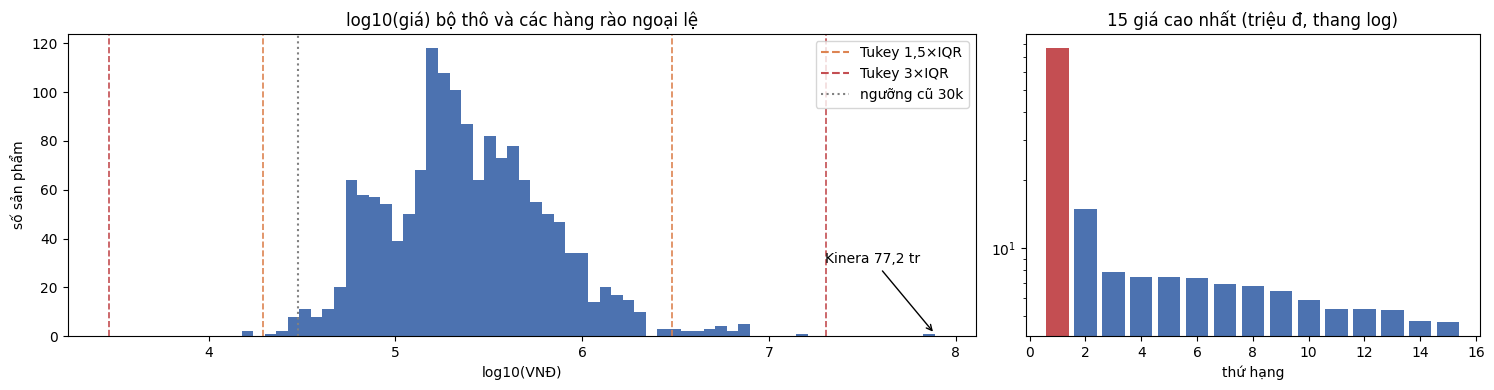

Tỉ lệ giữa 2 giá liền kề, đầu cao (giá thứ i / thứ i+1): [5.15 1.9  1.05 1.   1.01]
Tỉ lệ giữa 2 giá liền kề, đầu thấp: [1.14 1.23 1.19 1.04 1.03]


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [2, 1]})
ax[0].hist(y_raw, bins=60, color='#4C72B0')
for k, mau in [(1.5, '#DD8452'), (3, '#C44E52')]:
    for v in (q1 - k * iqr, q3 + k * iqr):
        ax[0].axvline(v, color=mau, ls='--', lw=1.2)
ax[0].plot([], [], color='#DD8452', ls='--', label='Tukey 1,5×IQR')
ax[0].plot([], [], color='#C44E52', ls='--', label='Tukey 3×IQR')
ax[0].axvline(np.log10(30_000), color='grey', ls=':', label='ngưỡng cũ 30k')
ax[0].annotate('Kinera 77,2 tr', (np.log10(77_245_000), 1), xytext=(7.3, 30), arrowprops=dict(arrowstyle='->'))
ax[0].set(title='log10(giá) bộ thô và các hàng rào ngoại lệ', xlabel='log10(VNĐ)', ylabel='số sản phẩm')
ax[0].legend()
top = raw['price'].sort_values(ascending=False).head(15).reset_index(drop=True) / 1e6
ax[1].bar(range(1, 16), top, color=['#C44E52'] + ['#4C72B0'] * 14)
ax[1].set(title='15 giá cao nhất (triệu đ, thang log)', xlabel='thứ hạng', yscale='log')
plt.tight_layout(); plt.show()
gia = raw['price'].sort_values(ascending=False).to_numpy()
print('Tỉ lệ giữa 2 giá liền kề, đầu cao (giá thứ i / thứ i+1):', np.round(gia[:5] / gia[1:6], 2))
gia_t = np.sort(raw['price'].to_numpy())
print('Tỉ lệ giữa 2 giá liền kề, đầu thấp:', np.round(gia_t[1:6] / gia_t[:5], 2))

**(2)–(3) Đọc từng sản phẩm ở hai đầu.** Đầu cao: mọi sản phẩm trên 5 triệu, kèm lượt bán và số đánh giá (bằng chứng có người mua thật ở mức giá đó).

In [14]:
cot = ['price', 'original_price', 'sold_num', 'review_count', 'seller_name', 'warranty_type', 'name']
raw.loc[raw['price'] > 5e6, cot].sort_values('price', ascending=False).style.format(
    {'price': '{:,.0f}', 'original_price': '{:,.0f}', 'sold_num': '{:,.0f}', 'review_count': '{:,.0f}'})

,price,original_price,sold_num,review_count,seller_name,warranty_type,name
1046,"77,245,000","100,318,000",nan,nan,The KoreaMart,Không bảo hành,"Kinera | Tai nghe Kinera Verdandi TWS phiên bản Flagship cao cấp nhất, hỗ trợ cả Bluetooth và có dây, 1DD"
46,"14,990,000",nan,50,7,Apple Flagship Store,Hóa đơn,Apple Airpods Max 2 - Hàng Chính Hãng
578,"7,890,000",nan,85,27,Bose,Bảo hành điện tử,Tai nghe Bose Ultra Open Earbuds | Immersive Audio
39,"7,499,000","9,519,000",nan,nan,Anker Vietnam,Bảo hành của nhà sản xuất quốc tế,[MỚI] Tai nghe không dây Soundcore Liberty 5 Pro Max | Trợ lý ghi chú AI | Hệ thống đàm thoại 10 cảm biến- D1204
30,"7,490,000","7,990,000",46,10,Sony Store Online,nan,Tai nghe Sony chống ồn không dây WF-1000XM6
37,"7,415,000","7,490,000",87,24,Bose,Bảo hành điện tử,Tai nghe Bose QuietComfort Ultra Earbuds 2
33,"6,990,000","10,450,000",54,19,MUSICLAND_SHOP,Bảo hành điện tử,Tai nghe Bluetooth chụp tai Sennheiser MOMENTUM 4 - Hàng chính hãng
25,"6,790,000",nan,488,98,Apple Flagship Store,Hóa đơn,Tai Nghe Không Dây Apple AirPods Pro 3 (MFHP4ZP/A) - Hàng Chính Hãng
28,"6,490,000","6,890,000","2,300",621,Sony Store Online,Không bảo hành,Tai nghe Sony không dây có công nghệ chống ồn WH-1000XM5
38,"5,890,000","7,290,000",76,21,SHOKZ,Hóa đơn,[MỞ BÁN] Tai Nghe Bluetooth Thể Thao Truyền Âm Thanh Qua Xương SHOKZ OPENSWIM PRO S710 - Tai nghe bơi lội - Chạy bộ - Bảo Hành 2 Năm Chính Hãng


In [15]:
# Đầu thấp: các sản phẩm dưới 40k (ngưỡng cũ 30k nằm giữa nhóm này)
cot = ['price', 'original_price', 'discount_pct', 'n_variants', 'sold_num', 'name']
thap = raw.loc[raw['price'] < 40_000, cot].sort_values('price').copy()
thap['nhom'] = np.where(thap['price'] < 30_000, '< 30k', '30k–40k')
print(thap.groupby('nhom').agg(so_dong=('price', 'size'), giam_gia_tv=('discount_pct', 'median'),
                               so_phan_loai_tv=('n_variants', 'median'), luot_ban_tv=('sold_num', 'median'),
                               co_gia_goc=('original_price', lambda s: s.notna().mean())))
thap.drop(columns='nhom').head(14).style.format({'price': '{:,.0f}', 'original_price': '{:,.0f}', 'sold_num': '{:,.0f}'})

         so_dong  giam_gia_tv  so_phan_loai_tv  luot_ban_tv  co_gia_goc
nhom                                                                   
30k–40k       22       47.000            2.000       74.000       0.955
< 30k         10       45.000            2.000      115.000       0.900


,price,original_price,discount_pct,n_variants,sold_num,name
114,"15,000",nan,nan,2.000000,10,"TAI NGHE BLUETOOTH S109 Tai Nghe Không Dây Kết Nối Bluetooth 5.0 Chống Ồn , CHỈNH ÂM LƯỢNG ,THIẾT KẾ NHỎ GỌN"
10,"17,062","53,168",68.000000,nan,"31,500",QIUWU Tai Nghe Không Dây Với Microphone Tai Nghe Khử Tiếng Ồn Tai Nghe Cho Lái Xe Audifonos ﻿ C
715,"21,000","34,000",38.000000,2.000000,153,Taidu mở Khuyên tai tai nghe bluetooth với tuổi thọ pin dài cho thể thao
238,"25,000","50,000",50.000000,3.000000,77,"Tai Nghe Blutooth 5.0 Đeo Cổ Thể Thao Pin Trâu Nghe Nhạc cực Hay, Đàm Thoại Bảo Hành 12 tháng"
105,"26,046","46,883",44.000000,12.000000,728,QIUWU Tai nghe dẫn khí bluetooth không dây âm thanh nổi HiFi xoay 180 ° tai nghe đơn móc tai giảm tiếng ồn có mic
272,"26,900","49,000",45.000000,5.000000,701,[GIÁ SỐC] Tai Nghe Bluetooth Mini S530 - Không Dây - Nhỏ gọn - Chống ồn - Tặng 1 dây sạc nhanh 25K - tai nghe giá rẻ - tai nghe nhét tai gaming hay giá rẻ
240,"26,900","50,000",46.000000,2.000000,15,tai nghe bluetooth kèm cáp sạc âm thanh êm hay nhỏ gọn - tai nghe bluetooth nhét tai không dây dùng được cho mọi dòng điện thoại
550,"27,000","40,000",33.000000,2.000000,6,Tai nghe bluetooth nhét tai Music cao cấp kèm mic đàm thoại siêu yêu COD
45,"29,538","53,168",44.000000,10.000000,"17,200",QIUWU Tai Nghe Không Dây Với Màn Hình Hiển Thị Kỹ Thuật Số Với Microphone Tai Nghe Khử Tiếng Ồn Tai Nghe Cho Lái Xe Audifonos ﻿ C
236,"29,994","55,000",45.000000,1.000000,20,Tai nghe Bluetooth - Tai nghe nhét tai không dây nghe gọi đàm thoại nghe nhạc cực hay (1 bên tai)


**Kết luận luật 3:**

| | Ngưỡng cũ (30k – 20 triệu) | Bằng chứng | Quyết định |
|---|---|---|---|
| **Đầu cao** | 20 triệu | Tukey 3×IQR trên log cho cận trên **20,1 triệu**; chỉ Kinera Verdandi 77,2 triệu vượt. Kinera đắt gấp **5,2 lần** sản phẩm kế tiếp (AirPods Max 2, 14,99 triệu), trong khi các bước giá khác ở đầu cao chỉ ~1–2 lần. Kinera có **0 lượt bán, 0 đánh giá**, "không bảo hành", bán qua shop trung gian → không có bằng chứng ai mua ở giá này. Các sản phẩm 5–15 triệu đều là flagship thật (Sony XM5/XM6, Bose, AirPods, Sennheiser) có lượt bán và đánh giá. | **Giữ 20 triệu** (làm tròn từ 20,1 triệu). Loại 1 dòng |
| **Đầu thấp** | 30 nghìn | Không quy tắc nào cho cận dưới gần 30k (Tukey 3×IQR ≈ 2,9k; MAD ≈ 7,5k; z-score ≈ 12k). Giá thấp nhất 15k chỉ cách giá kế tiếp 1,1 lần → không có khoảng trống. 10 sản phẩm dưới 30k giống nhóm 30–40k (TWS giá rẻ, có giá gốc, có giảm giá, có người mua; QIUWU 17k bán **31.500** cái). Mốc 30k là số tròn chọn theo cảm tính. | **Bỏ ngưỡng 30k**, dùng cận dưới Tukey 3×IQR (làm tròn 3.000 đ). Không loại dòng nào |

Vì sao chọn **Tukey 3×IQR trên log** thay vì 1,5×IQR: 1,5×IQR là ngưỡng "nghi ngờ", nó sẽ loại 20 tai nghe cao cấp thật (Sony, Bose, Apple), đúng những sản phẩm mô hình **cần** học; 3×IQR là ngưỡng "ngoại lệ cực đoan" chuẩn của Tukey. Ngưỡng được cố định thành hằng số trong `chung.py` (không tính lại mỗi lần chạy) để không phụ thuộc cách chia train/test.

KB-C-08 (GĐ1) vẫn kiểm tra độ nhạy: 3k–20tr vs không lọc vs 30k–20tr, chấm trên **cùng các dòng chung** để so công bằng.

### B1.3 Chuẩn hóa chuỗi (nhóm A)

**A1 + A3 – Tên shop.** Đây là sửa quan trọng nhất của B1: `seller_name` là **nhóm của GroupKFold**. Hai cách viết của cùng một shop sẽ thành hai nhóm, có thể rơi vào cả train và test → rò rỉ đúng thứ mà chia theo shop muốn tránh.

In [16]:
s = raw['seller_name'].dropna()
khoa = s.str.lower().str.strip()
nhieu_cach = s.groupby(khoa).agg(lambda x: dict(x.map(repr).value_counts()))
print(f'Số shop trước: {s.nunique()} | sau khi chuẩn hóa: {sach["seller_name"].nunique()}')
nhieu_cach[nhieu_cach.map(len) > 1].to_frame('các cách viết (repr để thấy dấu cách)')

Số shop trước: 330 | sau khi chuẩn hóa: 325


,các cách viết (repr để thấy dấu cách)
seller_name,
ginka,"{''GinKa\xa0'': 2, ''GinKa'': 2}"
prime supply_play life,"{''Prime Supply_Play Life'': 238, '' Prime Sup..."
vention flagship store,"{''Vention flagship store'': 3, '' Vention fla..."


Shop lớn nhất (**Prime Supply_Play Life, 238 dòng**, ~15% dữ liệu) bị tách làm hai chỉ vì một dấu cách ở đầu tên. Nếu không sửa, GroupKFold có thể đặt một phần shop này vào train, phần còn lại vào test.

**A2 – Giá trị giữ chỗ.** Shop không khai thông số thì trang điền chữ giữ chỗ. Các chữ này không phải giá trị thật; nếu giữ, chúng thành một mức phân loại giả ("Info Unavailable" thành một loại trở kháng).

In [17]:
dem = {c: raw[c].dropna().str.strip().loc[lambda v: v.str.lower().isin(chung.GIA_TRI_RONG)].value_counts().to_dict()
       for c in chung.COT_THONG_SO_CHU}
pd.Series({c: v for c, v in dem.items() if v}).to_frame('giá trị giữ chỗ → trống (số ô)')

,giá trị giữ chỗ → trống (số ô)
bluetooth_version,"{'Khác': 27, 'default': 2, 'Không áp dụng': 1,..."
waterproof,{'Not Rated': 1}
model,"{'Khác': 2, 'No': 1}"
driver_type,"{'Khác': 64, 'không': 1}"
impedance,"{'Info Unavailable': 126, 'No': 3, 'không': 1,..."


In [18]:
print('A4 – Nơi bán trước:', raw['location'].value_counts().loc[lambda v: v.index.str.contains('Hồ Chí Minh')].to_dict())
print('      sau        :', sach['location'].value_counts().loc[lambda v: v.index.str.contains('Hồ Chí Minh')].to_dict())
print('A1 – Tên sản phẩm có BOM / tab / nhiều khoảng trắng:',
      raw['name'].str.contains('\ufeff').sum(), '/', raw['name'].str.contains('\t').sum(), '/', raw['name'].str.contains(r'\s{2,}').sum())

A4 – Nơi bán trước: {'Thành phố Hồ Chí Minh': 339, 'Hồ Chí Minh': 4}
      sau        : {'Thành phố Hồ Chí Minh': 343}
A1 – Tên sản phẩm có BOM / tab / nhiều khoảng trắng: 2 / 1 / 72


### B1.4 Thông số sai đơn vị hoặc ngoài khoảng hợp lệ (C2, C3)

Thông số do shop tự khai. Giá trị **sai** được đặt thành trống (không bỏ dòng), để Imputer điền ở B3. Khoảng hợp lệ là hằng số `chung.KHOANG_HOP_LE`:

| Cột | Khoảng hợp lệ | Căn cứ |
|---|---|---|
| `bluetooth_version_num` | 4,0 – 6,1 | Các phiên bản Bluetooth SIG, 6.1 là bản mới nhất. Bluetooth 1 và 3 không còn trên tai nghe bán năm 2026 |
| `battery_hours_num` | 1 – 100 giờ | Tai nghe chụp tai flagship pin 72–80 giờ (Redmi Headphones Neo, UGREEN Max5c). 0 giờ vô nghĩa. Trên 100 giờ là cộng cả hộp sạc hoặc thời gian chờ |
| `impedance_ohm` | 4 – 200 Ω | Tai nghe Bluetooth có ampli trong, thường 16–64 Ω. 300 Ω là thông số của tai nghe có dây phòng thu |
| `warranty_months` | 0 – 60 tháng | Không có giá trị nào vượt |

Ngoài ra (C2): trở kháng ghi `mm` (cỡ driver) hoặc `dB` (độ nhạy) và giờ pin ghi "Chờ" (thời gian chờ) là **sai đơn vị**, đặt trống.

In [19]:
pin = raw.loc[raw['battery_hours_num'] > 100, ['battery_hours', 'battery_hours_num', 'price', 'seller_name', 'name']].sort_values('battery_hours_num')
c220 = pin[pin['battery_hours_num'] == 220]
print(f'Giờ pin > 100: {len(pin)} dòng. Riêng 220 giờ: {len(c220)} dòng, giá {c220["price"].min():,.0f}–{c220["price"].max():,.0f} đ')
pin.assign(name=pin['name'].str[:70]).tail(14).style.format({'price': '{:,.0f}'})

Giờ pin > 100: 28 dòng. Riêng 220 giờ: 15 dòng, giá 54,634–85,000 đ


,battery_hours,battery_hours_num,price,seller_name,name
136,220,220.000000,"59,000",Thành Công Storeone,"Tai Nghe i12 / Pro4 / Pro Có Bluetooth, Pin Nghe Nhạc 8–10 Giờ, Chống"
67,220,220.000000,"57,820",Đại Dương Technology,"Tai Nghe Bluetooth Pro Hỗ Trợ Kết Nối Không Dây, Thao Tác Sử Dụng Dễ D"
185,220,220.000000,"58,800",Đại Dương Technology,"( BÁN CHẠY ) Tai Nghe Bluetooth Không Dây Pro4 Thiết Kế Sang Trọng, Kế"
435,220,220.000000,"85,000",Đại Dương Technology,"Tai nghe Bluetooth cao cấp , Chống ồn , Dùng bluetooth 5.0, Thiết Kế H"
350,220,220.000000,"83,300",Đại Dương Technology,"Tai Bluetooth S20 A9 ANC, Tai nghe 3 chế độ kết nối , Tai Không Dây Có"
434,220,220.000000,"59,000",Công Nghệ Wifi Việt Nam,"( VUA GIÁ RẺ) Tai Nghe Không Dây Bluetooth i12 / Pro4 / Pro, Âm Bass"
156,220,220.000000,"57,820",TUẤN HƯNG PRO STORE,"Tai Nghe Bluetooth Không Dây Cảm Ứng , Thao tác sử dụng đơn giản , Doc"
243,220,220.000000,"59,000",TUẤN HƯNG PRO STORE,"( SIÊU PHẨM ) Tai nghe Bluetooth Pro Công Nghe Bluetooth Siêu Nhạy, Âm"
441,220,220.000000,"57,820",Đại Dương Technology,"Tai Nghe Không Dây Bluetooth i12 / Pro4 / Pro Âm Thanh Đỉnh Cao, Thiết"
167,300,300.000000,"188,000",ElecHome Concept Store,FUZHEN | Tai Nghe Bluetooth Không Dây Thật Âm Thanh Chất Lượng Cao Hủy


Cụm 220 giờ toàn là tai nghe i12/Pro4 giá ~55–85k, mô tả theo cùng một mẫu: tai nghe 60k không thể chạy 220 giờ (một sản phẩm trong cụm còn ghi trong tên "Pin nghe nhạc 8–10 giờ"). Các giá trị 72–100 giờ thuộc tai nghe chụp tai có thương hiệu (Redmi, UGREEN, Acer) là hợp lý nên giữ.

In [20]:
tk = raw.loc[(raw['impedance_ohm'] > 200) | (raw['impedance_ohm'] < 4) | raw['impedance'].str.contains('mm|dB', na=False),
             ['impedance', 'impedance_ohm', 'price', 'name']]
print('Trở kháng bị đặt trống:')
display(tk.assign(name=tk['name'].str[:60]).style.format({'price': '{:,.0f}'}))
bt = raw.loc[raw['bluetooth_version_num'].notna() & ~raw['bluetooth_version_num'].between(4, 6.1), ['bluetooth_version', 'bluetooth_version_num', 'price', 'name']]
print('Bluetooth bị đặt trống:')
display(bt.assign(name=bt['name'].str[:60]))

Trở kháng bị đặt trống:


,impedance,impedance_ohm,price,name
41,6.5mm,6.500000,"1,190,000","Tai nghe Samsung Galaxy Buds Core. Chống ồn chủ động ANC, Th"
60,300 ohm,300.000000,"90,000","Tai Nghe Bluetooth 5.2 S10 Pro Bản Quốc Tế Cao Cấp,Chốn"
132,300 ohm,300.000000,"240,000",♥Giới Hạn Miễn phí vận chuyển♥Xiaomi A520 điều khiển bằng cả
161,300 ohm,300.000000,"82,450",Tai Nghe Không Dây Bluetooth V5.0 F9 TWS Màn Hình LED Hiển T
198,300 ohm,300.000000,"59,000",Tai Nghe Chụp Tai Bluetooth P47
425,300 ohm,300.000000,"149,000",Tai Nghe Bluetooth HOCO Không Dây Nghe 1 Bên Tai nhỏ gọn cực
437,300 ohm,300.000000,"117,200",Tai Nghe không dây M45 SNOW LIGHT Bluetooth 5.3 Độ trễ thấp
738,1dB/mW,1.000000,"436,000",ZHANXINGZHE | Tai Nghe Bluetooth Siêu Nhỏ với Giảm Tiếng Ồn
749,210,210.000000,"279,000",HTC NE52 Tai Nghe Phiên Dịch AI 134 Ngôn Ngữ Kết Nối Blueto
752,320,320.000000,"399,999",HTC NE23 Tai nghe dịch bluetooth 6.0 Tai nghe khử tiếng ồn


Bluetooth bị đặt trống:


,bluetooth_version,bluetooth_version_num,price,name
282,3,3.000,"70,560.000",Rosy hốc máy ảnh phong cách retro Thiết kế tai...
998,1,1.000,"42,917.000",E-WOITD Mini Không Dây Bluetooblu-Tương Thích...


In [21]:
pd.DataFrame({c: {'trước: min': raw[c].min(), 'trước: max': raw[c].max(), 'trước: số ô có': raw[c].notna().sum(),
                  'sau: min': sach[c].min(), 'sau: max': sach[c].max(), 'sau: số ô có': sach[c].notna().sum()}
              for c in chung.KHOANG_HOP_LE}).T

,trước: min,trước: max,trước: số ô có,sau: min,sau: max,sau: số ô có
bluetooth_version_num,1.000,6.100,"1,061.000",4.000,6.100,"1,057.000"
battery_hours_num,0.000,480.000,448.000,1.000,100.000,414.000
impedance_ohm,0.500,320.000,862.000,8.000,160.000,844.000
warranty_months,0.000,24.000,437.000,0.000,24.000,437.000


### B1.5 Thương hiệu (C4, C5)

Ba vấn đề: (1) nhiều tên cùng nghĩa "không thương hiệu"; (2) cùng thương hiệu viết khác hoa/thường; (3) 23% trống, nhưng nhiều tên sản phẩm có dạng `THƯƠNG HIỆU | mô tả`.

In [22]:
b = raw['brand'].dropna().str.strip()
k = b.str.lower().str.strip(' .')
print('(1) Tên mang nghĩa không thương hiệu:', b[k.isin(chung.BRAND_KHONG_TH)].value_counts().to_dict())
g = b.groupby(k).agg(lambda s: dict(s.value_counts()))
print('(2) Cùng thương hiệu, nhiều cách viết:', g[g.map(len) > 1].to_dict())
tien_to = raw['name'].str.extract(r'^([^|【\[\(]{2,30}?)\s*\|')[0].str.strip()
ca_hai = raw['brand'].notna() & tien_to.notna() & ~raw['brand'].str.lower().isin(chung.BRAND_KHONG_TH)
khop = raw.loc[ca_hai, 'brand'].str.lower().str.strip(' .') == tien_to[ca_hai].str.lower()
print(f'(3) Khi có cả brand lẫn tiền tố "X |": tiền tố khớp brand ở {khop.mean():.0%} trong {ca_hai.sum()} dòng → tiền tố đáng tin để điền brand trống')
print('    Brand trống trước / sau:', raw['brand'].isna().sum(), '/', sach['brand'].isna().sum())
print('    Top thương hiệu sau làm sạch:', sach['brand'].value_counts().head(10).to_dict())

(1) Tên mang nghĩa không thương hiệu: {'No Brand': 175, 'OEM': 45, 'TWS': 27, 'Nobard': 10}
(2) Cùng thương hiệu, nhiều cách viết: {'fiil': {'fiil': np.int64(3), 'FIIL': np.int64(1)}, 'shuke': {'Shuke': np.int64(4), 'SHUKE': np.int64(2)}}
(3) Khi có cả brand lẫn tiền tố "X |": tiền tố khớp brand ở 98% trong 357 dòng → tiền tố đáng tin để điền brand trống
    Brand trống trước / sau: 361 / 299
    Top thương hiệu sau làm sạch: {'No Brand': 257, 'CHUBAN': 100, 'HTC': 88, 'Lenovo': 87, 'hoco': 38, 'Linkee': 32, 'UGREEN': 24, 'GOOJODOQ': 20, 'LS': 20, 'Anker': 18}


`TWS` (true wireless) là kiểu tai nghe, không phải thương hiệu; `Nobard` là gõ sai "No Brand"; `OEM` là hàng gia công không nhãn. Gộp cả ba vào `No Brand`. Các dòng không khớp tiền tố là trường hợp tiền tố là tên viết tắt hoặc dòng sản phẩm của cùng hãng (vd. `MC` của MCHOSE).

### B1.6 Cờ và những điểm ghi nhận nhưng không sửa ở B1

In [23]:
print('thieu_chi_tiet (timeout/app_only, không có thông số chi tiết):', sach['thieu_chi_tiet'].sum(), 'dòng')
print('sai_danh_muc (product_type sai, đã xóa):', sach['sai_danh_muc'].sum(), 'dòng')
print('dot_cao:', sach['dot_cao'].value_counts().to_dict())
print(pd.crosstab(sach['detail_status'], sach['seller_name'].isna()).rename(columns={False: 'có tên shop', True: 'thiếu tên shop'}))

thieu_chi_tiet (timeout/app_only, không có thông số chi tiết): 153 dòng
sai_danh_muc (product_type sai, đã xóa): 35 dòng
dot_cao: {'2026-11-19': 1101, '2026-11-13': 444}
seller_name    có tên shop  thiếu tên shop
detail_status                             
app_only                 2               2
ok                      48               0
ok_dom                1344               0
timeout                  1             148


In [24]:
pd.DataFrame([
    ('chat_response_rate trống 100%; is_sponsored, is_freeship, in_stock, is_new_seller chỉ 1 giá trị', 'B2: bỏ cột'),
    ('sku_id, is_lazmall, brand_id, shop_id… chỉ có ở đợt 13/11', 'B2: bỏ cột (KB-C-05)'),
    (f"review_count = 0 nhưng có rating_score: {((raw['review_count'] == 0) & raw['rating_score'].notna()).sum()} dòng", 'Cột rò rỉ, bị loại ở B0; không sửa'),
    (f"n_variants tới {raw['n_variants'].max():.0f} (shop liệt kê mọi tổ hợp màu × phiên bản)", 'B2/B3: cắt trần 20'),
    (f"shipping_fee > 300k: {(raw['shipping_fee'] > 300_000).sum()} dòng (hàng gửi từ nước ngoài)", 'B2/B3: lấy log'),
    (f"warranty_type = 'Không bảo hành' nhưng warranty_months > 0: {(raw['warranty_type'].eq('Không bảo hành') & raw['warranty_months'].gt(0)).sum()} dòng", 'Giữ warranty_months (ghi cụ thể hơn)'),
    ("2 dòng bán 'hai cặp' tai nghe (DX-16)", 'Giữ; quá ít để tạo cờ riêng'),
    (f"Tên có chữ Hán hoặc ngoặc trang trí 【】: {raw['name'].str.contains('[一-鿿【】]').sum()} dòng", 'B3: chuẩn hóa tên trước TF-IDF'),
], columns=['Ghi nhận', 'Xử lý ở đâu'])

,Ghi nhận,Xử lý ở đâu
0,"chat_response_rate trống 100%; is_sponsored, i...",B2: bỏ cột
1,"sku_id, is_lazmall, brand_id, shop_id… chỉ có ...",B2: bỏ cột (KB-C-05)
2,review_count = 0 nhưng có rating_score: 7 dòng,"Cột rò rỉ, bị loại ở B0; không sửa"
3,n_variants tới 676 (shop liệt kê mọi tổ hợp mà...,B2/B3: cắt trần 20
4,shipping_fee > 300k: 75 dòng (hàng gửi từ nước...,B2/B3: lấy log
5,warranty_type = 'Không bảo hành' nhưng warrant...,Giữ warranty_months (ghi cụ thể hơn)
6,2 dòng bán 'hai cặp' tai nghe (DX-16),Giữ; quá ít để tạo cờ riêng
7,Tên có chữ Hán hoặc ngoặc trang trí 【】: 31 dòng,B3: chuẩn hóa tên trước TF-IDF


### B1.7 Kiểm tra sau làm sạch

Các điều kiện dưới đây phải đúng; nếu sau này ai sửa `lam_sach()` làm hỏng, ô này báo lỗi ngay.

In [25]:
kiem_tra = {
    'item_id không trùng': sach['item_id'].is_unique,
    'không còn tin đăng trùng (tên + shop + giá)': not sach.duplicated(['name', 'seller_name', 'price']).any(),
    'giá trong khoảng ngưỡng': sach['price'].between(chung.GIA_MIN, chung.GIA_MAX).all(),
    'name, price không trống': sach[['name', 'price']].notna().all().all(),
    'không còn khoảng trắng thừa ở tên/shop/brand': not any(sach[c].dropna().ne(sach[c].dropna().str.strip()).any() for c in ['name', 'seller_name', 'brand']),
    'tên shop không còn trùng do hoa/thường': sach['seller_name'].nunique() == sach['seller_name'].str.lower().nunique(),
    'không còn giá trị giữ chỗ': not any(sach[c].str.lower().isin(chung.GIA_TRI_RONG).any() for c in chung.COT_THONG_SO_CHU),
    'thông số trong khoảng hợp lệ': all(sach[c].dropna().between(lo, hi).all() for c, (lo, hi) in chung.KHOANG_HOP_LE.items()),
    'product_type chỉ còn loại tai nghe hoặc trống': (sach['product_type'].isin(chung.LOAI_TAI_NGHE) | sach['product_type'].isna()).all(),
    'không còn brand OEM / TWS / Nobard': not sach['brand'].str.lower().isin(chung.BRAND_KHONG_TH - {'no brand'}).any(),
}
for k, v in kiem_tra.items():
    print('✔' if v else '✘', k)
assert all(kiem_tra.values()), 'Có điều kiện không đạt'
print(f"\nKết quả: {len(raw)} → {len(sach)} dòng | {sach['seller_name'].nunique()} shop | giá {sach['price'].min():,.0f} – {sach['price'].max():,.0f} đ")

✔ item_id không trùng
✔ không còn tin đăng trùng (tên + shop + giá)
✔ giá trong khoảng ngưỡng
✔ name, price không trống
✔ không còn khoảng trắng thừa ở tên/shop/brand
✔ tên shop không còn trùng do hoa/thường
✔ không còn giá trị giữ chỗ
✔ thông số trong khoảng hợp lệ
✔ product_type chỉ còn loại tai nghe hoặc trống
✔ không còn brand OEM / TWS / Nobard

Kết quả: 1550 → 1545 dòng | 325 shop | giá 15,000 – 14,990,000 đ


In [26]:
sach.to_csv('../' + chung.DUONG_DAN_SACH, index=False, encoding='utf-8-sig')
print('Đã lưu', chung.DUONG_DAN_SACH, sach.shape)

Đã lưu data/lazada_sach.csv (1545, 77)


**Kết quả B1:** bảng số dòng và bảng số ô bị sửa (B1.1) đưa thẳng vào báo cáo mục 2. File `data/lazada_sach.csv` là đầu vào của B2 (EDA) và B3 (đặc trưng); file này chưa phải `abt_gia.csv`.